# Cálculo Automático de $K$ e $z$ (LGR) e Validação Comparativa na Simulação

> A modelagem física completa e o memorial de cálculo analítico passo a passo encontram-se em [`projeto.md`](projeto.md).
>
> Este notebook complementar realiza:
> 1. **O cálculo automático de $z$, $K$ e dos ganhos $(K_p, K_i, K_d)$** via Lugar Geométrico das Raízes (LGR);
> 2. **A tabela comparativa de diferentes pares $(UP_{\text{des}}, T_{s,\text{des}})$** em ambiente simulado e o **gráfico de validação da resposta ao degrau em malha fechada**.

In [1]:
import control as ct
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
# 1. Parâmetros físicos convertidos para o Sistema Internacional (SI)
g = 9.81  # Aceleração da gravidade (m/s^2)
l = 0.29  # Comprimento: 29 cm -> 0.29 m
m = 0.0085  # Massa: 8.5 g -> 0.0085 kg

# 2. Cálculo dos termos da Função de Transferência
J = m * (l**2)  # Momento de inércia (m * l^2)
num_val = 1 / J  # Numerador: 1 / (m * l^2)
den_val = g / l  # Termo constante do denominador: g / l

# 3. Montagem da FT: G(s) = (1/ml^2) / (s^2 - g/l)
s = ct.tf("s")
G_s = num_val / (s**2 - den_val)

In [4]:
# 1. FUNÇÃO PARA ACHAR ZETA, WN E POLOS DOMINANTES
def calcular_polos_dominantes(up_percent, ts, criterio_ts=0.02, verbose=True):
  """Calcula o fator de amortecimento (zeta), frequência natural (wn)

  e os polos dominantes de 2ª ordem a partir de UP (%) e Ts (s).
  """
  up = up_percent / 100.0

  # Cálculo do fator de amortecimento (zeta)
  zeta = -np.log(up) / np.sqrt(np.pi**2 + (np.log(up)) ** 2)

  # Fator do numerador de Ts (4 para critério de 2%, 3 para critério de 5%)
  fator_criterio = 4.0 if criterio_ts == 0.02 else 3.0
  wn = fator_criterio / (zeta * ts)

  # Parte real (sigma_d) e imaginária amortecida (wd)
  sigma_d = zeta * wn
  wd = wn * np.sqrt(1 - zeta**2)

  # Par de polos complexos conjugados
  sd_pos = complex(-sigma_d, wd)
  sd_neg = complex(-sigma_d, -wd)

  if verbose:
    print("=== PARÂMETROS DE 2ª ORDEM E POLOS DOMINANTES ===")
    print(
        f"Entrada: UP% = {up_percent:.1f}% | Ts = {ts} s (Critério"
        f" {int(criterio_ts*100)}%)"
    )
    print(f"Fator de Amortecimento (zeta): {zeta:.4f}")
    print(f"Frequência Natural (wn):       {wn:.4f} rad/s")
    print(f"Polos Dominantes (sd):         {-sigma_d:.4f} ± j{wd:.4f}\n")

  return {
      "zeta": zeta,
      "wn": wn,
      "sigma_d": sigma_d,
      "wd": wd,
      "sd": sd_pos,
      "polos": (sd_pos, sd_neg),
  }

In [5]:
def projetar_pid_lgr(G_s, sd, verbose=True):
  """Calcula a posição do zero duplo (-z) e os ganhos Kp, Ki, Kd via LGR."""
  s = ct.tf("s")
  polos_planta = ct.poles(G_s)
  sigma_d = -np.real(sd)
  wd = np.imag(sd)

  # Condição de Fase: soma dos ângulos dos polos (incluindo integrador em s=0)
  ang_integrador = np.angle(sd)
  ang_polos_planta = sum(np.angle(sd - p) for p in polos_planta)
  soma_ang_polos = ang_integrador + ang_polos_planta

  # Ângulo necessário para cada um dos 2 zeros repetidos: 2*phi_z - soma_polos = -pi
  phi_z = (soma_ang_polos - np.pi) / 2.0

  # Posição de z: tan(phi_z) = wd / (z - sigma_d) => z = sigma_d + wd / tan(phi_z)
  z = sigma_d + (wd / np.tan(phi_z))

  # Condição de Módulo: |((sd + z)^2 / sd) * G(sd)| * Kd = 1
  G_sd = ct.evalfr(G_s, sd)
  C_base_sd = ((sd + z) ** 2) / sd
  Kd = 1.0 / np.abs(C_base_sd * G_sd)

  # Ganhos Kp e Ki
  Kp = 2.0 * Kd * z
  Ki = Kd * (z**2)

  # Funções de Transferência resultantes
  C_s = (Kd * s**2 + Kp * s + Ki) / s
  L_s = C_s * G_s
  T_mf = ct.feedback(L_s, 1)
  Filtro_ref = (z**2) / (s + z) ** 2
  T_mf_filtrada = T_mf * Filtro_ref

  if verbose:
    print("=== PROJETO DO CONTROLADOR PID (LGR - ZEROS REPETIDOS) ===")
    print(f"Ângulo de cada zero (phi_z): {np.degrees(phi_z):.2f}°")
    print(f"Zero Duplo (-z):             s = -{z:.4f}")
    print(f"Ganhos: Kp = {Kp:.6f} | Ki = {Ki:.6f} | Kd = {Kd:.6f}\n")

  return {
      "z": z,
      "Kp": Kp,
      "Ki": Ki,
      "Kd": Kd,
      "C_s": C_s,
      "L_s": L_s,
      "T_mf": T_mf,
      "T_mf_filtrada": T_mf_filtrada,
  }

In [6]:
def avaliar_projeto_pid(UP_desejado, Ts_desejado, G_planta=G_s, criterio_ts=0.02, verbose=False):
  """
  Projeta o PID via LGR para (UP_desejado, Ts_desejado) e executa a validação
  na simulação ao degrau (sem filtro).
  """
  res_polos = calcular_polos_dominantes(
      up_percent=UP_desejado, ts=Ts_desejado, criterio_ts=criterio_ts, verbose=verbose
  )
  res_pid = projetar_pid_lgr(G_planta, res_polos["sd"], verbose=verbose)

  Gmf = res_pid["T_mf"]  # Malha fechada sem filtro
  polos_mf = ct.poles(Gmf)
  estavel_mf = bool(np.all(np.real(polos_mf) < 0)) and (res_pid["z"] > 0) and (res_pid["Kd"] > 0)

  if estavel_mf:
    info_degrau = ct.step_info(Gmf)
    up_sim = float(info_degrau["Overshoot"])
    ts_sim = float(info_degrau["SettlingTime"])
    tr_sim = float(info_degrau["RiseTime"])
    pico_sim = float(info_degrau["Peak"])
  else:
    up_sim = np.nan
    ts_sim = np.nan
    tr_sim = np.nan
    pico_sim = np.nan

  sd = res_polos["sd"]
  z_val = res_pid["z"]
  p_grav = float(np.max(np.real(ct.poles(G_planta))))  # +sqrt(g/l) = 5.8161 rad/s

  return {
      "UP_des (%)": UP_desejado,
      "Ts_des (s)": Ts_desejado,
      "zeta": res_polos["zeta"],
      "wn (rad/s)": res_polos["wn"],
      "Polo Dominante (sd)": f"{np.real(sd):.2f} ± j{abs(np.imag(sd)):.2f}",
      "s = -z (rad/s)": -z_val,
      "z (rad/s)": z_val,
      "K = Kd": res_pid["Kd"],
      "Kp": res_pid["Kp"],
      "Ki": res_pid["Ki"],
      "UP_sim (%)": up_sim,
      "Ts (s)": ts_sim,
      "Tr (s)": tr_sim,
      "Resposta (z vs grav)": "Rápido" if z_val > p_grav else "Lento",
      "Gmf": Gmf,
      "res_pid": res_pid,
      "res_polos": res_polos,
  }


def comparar_lista_projetos(lista_up_ts, G_planta=G_s, plotar_degrau=True):
  """
  Recebe uma lista de tuplas (UP_desejado, Ts_desejado), avalia cada projeto
  e monta uma tabela com s = -z, K = Kd e a validação ao degrau (sem filtro).
  """
  resultados = [avaliar_projeto_pid(up, ts, G_planta=G_planta) for up, ts in lista_up_ts]

  colunas_tabela = [
      "UP_des (%)",
      "Ts_des (s)",
      "Polo Dominante (sd)",
      "s = -z (rad/s)",
      "K = Kd",
      "Kp",
      "Ki",
      "UP_sim (%)",
      "Ts (s)",
      "Tr (s)",
      "Resposta (z vs grav)",
  ]
  df = pd.DataFrame([{k: r[k] for k in colunas_tabela} for r in resultados])

  if plotar_degrau:
    plt.figure(figsize=(10, 5))
    t_vec = np.linspace(0, 2.5, 1500)
    for r in resultados:
      if not np.isnan(r["UP_sim (%)"]):
        t_out, y_out = ct.step_response(r["Gmf"], T=t_vec)
        label = (
            f"UP={r['UP_des (%)']:.0f}%, Ts={r['Ts_des (s)']}s "
            f"(s={r['s = -z (rad/s)']:.2f}, K={r['K = Kd']:.5f})"
        )
        plt.plot(t_out, y_out, label=label)
    plt.axhline(1.0, color="black", linestyle="--", linewidth=0.9, label="Referência (Degrau = 1)")
    plt.title("Validação na Simulação: Resposta ao Degrau em Malha Fechada")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Ângulo Normalizado θ(t)")
    plt.grid(True, alpha=0.35)
    plt.legend(fontsize=8.5, loc="upper right")
    plt.tight_layout()
    plt.show()

  return df, resultados

### 1. Cálculo Automático de $K$ e $z$ (Projeto Principal: $UP = 5\%$, $T_s = 0,5\text{ s}$)

In [5]:
UP_desejado = 5.0  # 5%
Ts_desejado = 0.5  # 0.5 segundos

caso = avaliar_projeto_pid(UP_desejado, Ts_desejado, verbose=True)


=== PARÂMETROS DE 2ª ORDEM E POLOS DOMINANTES ===
Entrada: UP% = 5.0% | Ts = 0.5 s (Critério 2%)
Fator de Amortecimento (zeta): 0.6901
Frequência Natural (wn):       11.5924 rad/s
Polos Dominantes (sd):         -8.0000 ± j8.3895

=== PROJETO DO CONTROLADOR PID (LGR - ZEROS REPETIDOS) ===
Ângulo de cada zero (phi_z): 103.48°
Zero Duplo (-z):             s = -5.9888
Ganhos: Kp = 0.186868 | Ki = 0.559556 | Kd = 0.015601



### 2. Tabela de Comparação em Ambiente Simulado e Gráfico de Validação

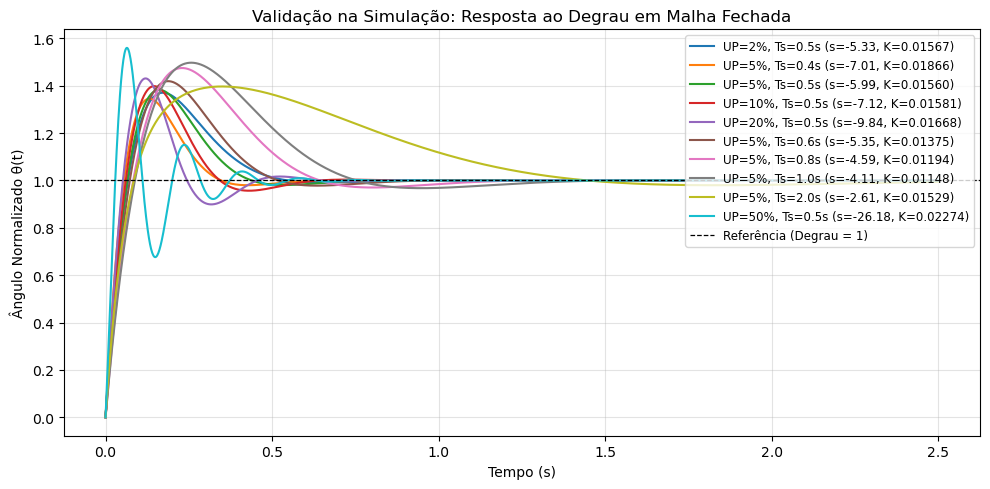

,UP_des (%),Ts_des (s),Polo Dominante (sd),s = -z (rad/s),K = Kd,Kp,Ki,UP_sim (%),Ts (s),Tr (s),Resposta (z vs grav)
0,2.0,0.50,-8.00 ± j6.42,-5.3343,0.015674,0.167224,0.446015,37.04,0.4945,0.0471,Lento
1,5.0,0.40,-10.00 ± j10.49,-7.0086,0.018663,0.261599,0.916714,34.43,0.3313,0.0457,Rápido
2,5.0,0.50,-8.00 ± j8.39,-5.9888,0.015601,0.186868,0.559556,38.21,0.4073,0.0479,Rápido
3,10.0,0.50,-8.00 ± j10.92,-7.1176,0.015811,0.225078,0.801009,39.83,0.5474,0.0456,Rápido
4,20.0,0.50,-8.00 ± j15.62,-9.8361,0.016679,0.328120,1.613712,43.03,0.4282,0.0381,Rápido
5,5.0,0.60,-6.67 ± j6.99,-5.3505,0.013749,0.147130,0.393612,41.95,0.6859,0.0591,Lento
6,5.0,0.80,-5.00 ± j5.24,-4.5906,0.011943,0.109653,0.251689,47.46,0.9489,0.0698,Lento
7,5.0,1.00,-4.00 ± j4.19,-4.1066,0.011483,0.094309,0.193642,49.76,1.1627,0.0684,Lento
8,5.0,2.00,-2.00 ± j2.10,-2.6131,0.015290,0.079907,0.104402,39.71,1.8421,0.0635,Lento
9,50.0,0.50,-8.00 ± j36.26,-26.1778,0.022741,1.190599,15.583604,55.58,0.4452,0.0202,Rápido


In [ ]:
# ==========================================================================
# LISTA DE VALORES (UP_desejado [%], Ts_desejado [s]) PARA TESTAR E COMPARAR
# Adicione ou altere qualquer par (UP_desejado, Ts_desejado) nesta lista:
# ==========================================================================
lista_testes = [
    (2.0, 0.5),
    (5.0, 0.4),
    (5.0, 0.5),   # <-- Projeto de referência
    (10.0, 0.5),
    (20.0, 0.5),
    (5.0, 0.6),
    (5.0, 0.8),
    (5.0, 1.0),
    (5.0, 2.0),
    (50.0, 0.5)
]

tabela_projetos, lista_resultados = comparar_lista_projetos(lista_testes, plotar_degrau=True)

# Formatação amigável da tabela
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
display(
    tabela_projetos.style.format({
        "UP_des (%)": "{:.1f}",
        "Ts_des (s)": "{:.2f}",
        "s = -z (rad/s)": "{:.4f}",
        "K = Kd": "{:.6f}",
        "Kp": "{:.6f}",
        "Ki": "{:.6f}",
        "UP_sim (%)": "{:.2f}",
        "Ts (s)": "{:.4f}",
        "Tr (s)": "{:.4f}",
    })
)